In [3]:
%load_ext autoreload
%autoreload 2
# automatically pick up changes made in src file

# LEDGAR: supervised models (logistic regression + Complement Naive Bayes)
Loads the features saved by `preprocess.ipynb` (run that once first), then trains, evaluates and compares both models.

**Flow**
1. Imports
2. Load saved features + labels
3. Evaluator (scores every model the same way)
4. Model 1: multiclass softmax logistic regression
5. Model 2: Complement Naive Bayes (alpha / norm tuning)
6. Compare the models (validation)
7. Error analysis (validation)
8. Save the trained models
9. Test (ONCE, at the very end)

`src/models.py` only TRAINS. All validating and testing happens through `src/sup_eval_metrics.py`.

## 1. Imports
All src files are imported here, once.

In [4]:
from pathlib import Path
import sys; sys.path.append('..')     # lets the notebook find the src folder

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
import joblib

from src.models import MultiClassLogisticRegression, ComplementNaiveBayes   # model classes (train only)
from src.sup_eval_metrics import SupervisedEvaluator                       # scores any trained model
from src.classification_error_analysis import ErrorAnalysis                # error analysis class

## 2. Load the saved features (made by `preprocess.ipynb`)
No cleaning, lemmatising or TF-IDF here - everything is read from disk in seconds.
- `x_train`, `x_val`, `x_test`: TF-IDF matrices (sparse)
- `vectorizer` / `feature_names`: the fitted TF-IDF and its column (word) names
- `proc_train`, `proc_val`, `proc_test`: the lemmatised clauses with labels

In [5]:
processed = Path("../data/processed")
features = Path("../data/features")

# TF-IDF matrices
x_train = sparse.load_npz(features / "x_train.npz")
x_val = sparse.load_npz(features / "x_val.npz")
x_test = sparse.load_npz(features / "x_test.npz")

# fitted vectoriser and its column (word) names
vectorizer = joblib.load(features / "vectorizer.joblib")
feature_names = vectorizer.get_feature_names_out()

# lemmatised clauses (text + labels)
proc_train = pd.read_parquet(processed / "proc_train.parquet")
proc_val = pd.read_parquet(processed / "proc_validation.parquet")
proc_test = pd.read_parquet(processed / "proc_test.parquet")

print("x_train:", x_train.shape, "| x_val:", x_val.shape, "| x_test:", x_test.shape)

x_train: (59933, 213105) | x_val: (10000, 213105) | x_test: (10000, 213105)


Labels
- y = the label column of each split: y_train, y_val, y_test
- `label_names`: lookup from label number to clause name, e.g. 47 → "Governing Laws"

In [6]:
y_train = proc_train.label
y_val = proc_val.label
y_test = proc_test.label

# pairs each number with its name, then makes a lookup dictionary
# zip lines up the two columns side by side
label_names = dict(zip(proc_train["label"], proc_train["label_name"]))

## 3. Evaluator
Stores the data splits ONCE. Every model is then scored the same way:
- `evaluate(model)`: train + validation + gap - compare train with validation to check for overfitting
- `validate(model)`: score on validation - unseen data, used to choose settings
- `compare({...})`: side-by-side table of several models
- `eval_test(model)`: final exam - run ONCE at the very end

Bias / variance: training error high → bias (underfitting); gap (val error − train error) big → variance (overfitting).

In [7]:
ev = SupervisedEvaluator(x_train, y_train, x_val, y_val, x_test, y_test)  # x and y in pairs: train, val, test
# make sure the evaluator has the variables and then train model, then use initialised evaluate to val, test, and get metrics

## 4. Model 1: multiclass softmax logistic regression
## ML flow imeplementation as well
- `train()`: learn the weights (train data only)
- the trained model is kept in `lr` and passed to the evaluator - no retraining between validation and test
- Train model with particular hyperparameters - record scores in MLFLOW 

In [1]:
import mlflow
mlflow.set_tracking_uri("sqlite:///../mlflow.db")  # set the tracking URI to a local SQLite database, local repo root 
mlflow.set_experiment("ledgar-clause-classifiere")  # set the experiment name to "text_classification"


c:\Users\jagmeet\vsc\py_ld\legal_venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/11/09 11:52:28 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/09 11:52:28 INFO mlflow.store.db.utils: Updating database tables
2026/11/09 11:52:30 INFO mlflow.tracking.fluent: Experiment with name 'ledgar-clause-classifiere' does not exist. Creating a new experiment.


<Experiment: artifact_location='file:c:/Users/jagmeet/vsc/py_ld/notebooks/mlruns/1', creation_time=1794225150457, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1794225150457, lifecycle_stage='active', name='ledgar-clause-classifiere', tags={}, trace_location=None, workspace='default'>

- C controls how much freedom the model has. It’s the opposite of the λ regularisation parameter (reduces overfitting)
- high C - oppose regularisation more - slightly promote a more complex fitted model 
- low C - agrees with regularisation - allows for overfitting to be controlled and pushes a simpler model

In [10]:
for c in [0.1, 1.0, 10.0]:  # hyperparameter search for C# since C = 30 IS OVERFITTING
    with mlflow.start_run(run_name=f'logreg_c{c}_balanced'):
        # different names from the final model, so lr and scores_lr aren't overwritten
        lr_tune = MultiClassLogisticRegression(C=c, class_weight='balanced').train(x_train, y_train)  # learn weights
        # the model guesses train + validation labels, and they're marked
        val_preds_tune, scores_tune = ev.evaluate(lr_tune.model)

        # settings: read from the model itself
        mlflow.log_params(lr_tune.model.get_params())  # log model hyperparameters
        mlflow.log_param('tfidf_ngram_range', vectorizer.ngram_range)  # log vectorizer hyperparameters

        # log metrics for validation set from dictionary of evaluate class (from metrics py)
        mlflow.log_metrics({
            "train_macro_f1": scores_tune["train"]["macro_f1"],
            "val_macro_f1": scores_tune["validation"]["macro_f1"],
            "val_accuracy": scores_tune["validation"]["accuracy"],
            "gap": scores_tune["gap"],
        })

Settings: C=0.1, class_weight=balanced
Training multiclass softmax logistic regression...
Number of classes: 100
train      accuracy 0.8024 | macro F1 0.7553 | error 0.2447
validation accuracy 0.7813 | macro F1 0.7050 | error 0.2950
gap        0.0502  (validation error - train error)
Settings: C=1.0, class_weight=balanced
Training multiclass softmax logistic regression...
Number of classes: 100
train      accuracy 0.9045 | macro F1 0.8948 | error 0.1052
validation accuracy 0.8413 | macro F1 0.7812 | error 0.2188
gap        0.1136  (validation error - train error)
Settings: C=10.0, class_weight=balanced
Training multiclass softmax logistic regression...
Number of classes: 100
train      accuracy 0.9854 | macro F1 0.9861 | error 0.0139
validation accuracy 0.8686 | macro F1 0.8111 | error 0.1889
gap        0.1750  (validation error - train error)


## 5. Model 2: Complement Naive Bayes
Since the model initially started with underfitting (training error ~20%), test different alpha levels.
Lower alpha = less smoothing = less bias, more variance. Pick the best **validation** macro F1.

In [9]:
# since the model intiially started with underfitting start with two different levels of normalisation and a range of alpha values to see which combination gives the best results
# run the loop and the MLFLOW records inside the lloop for each combination of alpha and normalisation
# cnb, evaluation, dictionary of results, and then log the parameters and metrics for each run
# results should be visible in the MLFLOW UI, and then the best model can be selected and used for testing

for norm in [False, True]:
    for a in [1.0, 0.3, 0.1, 0.03, 0.01]:
        with mlflow.start_run(run_name = f'cnb_alpha{a}_norm{norm}'):
            cnb = ComplementNaiveBayes(alpha=a, norm=norm).train(x_train, y_train)
            val_preds_cnb, scores_cnb = ev.evaluate(cnb.model)

            mlflow.log_params(cnb.model.get_params())
            mlflow.log_param('tfidf_ngram_range', vectorizer.ngram_range)

            # log metrics for validation set from dictionary of evaluate class (from metrics py)
            mlflow.log_metrics({
                "train_macro_f1": scores_cnb["train"]["macro_f1"],
                "val_macro_f1": scores_cnb["validation"]["macro_f1"],
                "val_accuracy": scores_cnb["validation"]["accuracy"],
                "gap": scores_cnb["gap"],
            })

Settings: alpha=1.0, norm=False
Training complement naive bayes model on imbalanced class x train dataset
 Number of classes: 100
train      accuracy 0.8685 | macro F1 0.7972 | error 0.2028
validation accuracy 0.8124 | macro F1 0.7016 | error 0.2984
gap        0.0956  (validation error - train error)
Settings: alpha=0.3, norm=False
Training complement naive bayes model on imbalanced class x train dataset
 Number of classes: 100
train      accuracy 0.8829 | macro F1 0.8215 | error 0.1785
validation accuracy 0.8183 | macro F1 0.7099 | error 0.2901
gap        0.1116  (validation error - train error)
Settings: alpha=0.1, norm=False
Training complement naive bayes model on imbalanced class x train dataset
 Number of classes: 100
train      accuracy 0.8903 | macro F1 0.8325 | error 0.1675
validation accuracy 0.8209 | macro F1 0.7160 | error 0.2840
gap        0.1165  (validation error - train error)
Settings: alpha=0.03, norm=False
Training complement naive bayes model on imbalanced class x t

## MLflow conclusions - run 1 
- **Logistic regression:** the best model at 0.815, but it overfits (train 0.995, gap 0.18). Best parameters so far: C=30, class_weight='balanced', with lower C values still to test.
- **Complement Naive Bayes:** limited by bias (train about 0.83), and tuning alpha only adds about 1.5 points in total (0.702 to 0.716). Ideal parameters: alpha=0.1, norm=False, the simplest setting once the gains flatten.

## MLflow conclusions - run 2 
- **Logistic regression:** the best model at 0.811, still overfitting (train 0.986, gap 0.175). Lowering C shrank the gap but also lowered validation F1 (0.705 at C=0.1), so regularisation does not fix it. 
- C=30 added only 0.4 points. Ideal parameters: C=10, class_weight='balanced'.

## Final models and hyperparameters

In [11]:
with mlflow.start_run(run_name = 'logreg_final_c10'):
    lr = MultiClassLogisticRegression(C=10, class_weight='balanced').train(x_train, y_train)
    val_preds_lr, scores_lr = ev.evaluate(lr.model)

    mlflow.log_params(lr.model.get_params())
    mlflow.log_param('tfidf_ngram_range', vectorizer.ngram_range)

    # log metrics for validation set from dictionary of evaluate class (from metrics py)
    mlflow.log_metrics({
        "train_macro_f1": scores_lr["train"]["macro_f1"],
        "val_macro_f1": scores_lr["validation"]["macro_f1"],
        "val_accuracy": scores_lr["validation"]["accuracy"],
        "gap": scores_lr["gap"],
    })
    mlflow.sklearn.log_model(lr.model, 'model_lr_final')

Settings: C=10, class_weight=balanced
Training multiclass softmax logistic regression...
Number of classes: 100
train      accuracy 0.9854 | macro F1 0.9861 | error 0.0139


2026/11/09 14:29:49 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


validation accuracy 0.8686 | macro F1 0.8111 | error 0.1889
gap        0.1750  (validation error - train error)


In [12]:
# final model for Complement Naive Bayes
with mlflow.start_run(run_name = 'cnb_final_alpha0.1_normFalse'):
    cnb = ComplementNaiveBayes(alpha=0.1, norm=False).train(x_train, y_train)
    val_preds_cnb, scores_cnb = ev.evaluate(cnb.model)

    mlflow.log_params(cnb.model.get_params())
    mlflow.log_param('tfidf_ngram_range', vectorizer.ngram_range)

    # log metrics for validation set from dictionary of evaluate class (from metrics py)
    mlflow.log_metrics({
        "train_macro_f1": scores_cnb["train"]["macro_f1"],
        "val_macro_f1": scores_cnb["validation"]["macro_f1"],
        "val_accuracy": scores_cnb["validation"]["accuracy"],
        "gap": scores_cnb["gap"],
    })
    mlflow.sklearn.log_model(cnb.model, 'model_cnb_final')

Settings: alpha=0.1, norm=False
Training complement naive bayes model on imbalanced class x train dataset
 Number of classes: 100
train      accuracy 0.8903 | macro F1 0.8325 | error 0.1675


2026/11/09 14:30:34 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


validation accuracy 0.8209 | macro F1 0.7160 | error 0.2840
gap        0.1165  (validation error - train error)


## 6. Compare the models (validation only)

In [13]:
ev.compare({"Logistic regression (C=30, balanced)": lr.model,
            "Complement NB (alpha=0.1)": cnb.model})

--- Logistic regression (C=30, balanced) ---
train      accuracy 0.9854 | macro F1 0.9861 | error 0.0139
validation accuracy 0.8686 | macro F1 0.8111 | error 0.1889
gap        0.1750  (validation error - train error)
--- Complement NB (alpha=0.1) ---
train      accuracy 0.8903 | macro F1 0.8325 | error 0.1675
validation accuracy 0.8209 | macro F1 0.7160 | error 0.2840
gap        0.1165  (validation error - train error)


,train macro F1,val macro F1,val accuracy,gap
model,,,,
"Logistic regression (C=30, balanced)",0.9861,0.8111,0.8686,0.1750
Complement NB (alpha=0.1),0.8325,0.7160,0.8209,0.1165


## 7. Error analysis (validation set)
Uses `src/classification_error_analysis.py` → `ErrorAnalysis` class. Validation shows authentic weaknesses on unseen data.
1. Per-class scores, worst F1 first: which clause types are weak?
2. TP / FP / FN / TN per clause type
3. Top confused pairs: which types get mixed up with which?
4. One weak class in detail: where did its clauses go?
5. Read the actual wrong clauses
6. Confusion matrix picture (overview)
7. Group the mistakes into 3-4 reasons and count them (e.g. overlapping labels / too rare / long or merged clauses)

### 7a. Logistic regression

In [17]:
ea = ErrorAnalysis(y_true=y_val, y_pred=val_preds_lr,
                   label_names=label_names,
                   classes=lr.model.classes_,       # fixed order: same 100 classes in every table
                   texts=proc_val["text"])           # original clause text, to read mistakes

In [18]:
# 1. per-class scores - worst F1 first (check the support column: are the worst ones small classes?)
ea.report_df().head(15)

,precision,recall,f1-score,support
Books,0.000000,0.000000,0.000000,0
Assigns,0.333333,0.333333,0.333333,3
Applicable Laws,0.328947,0.362319,0.344828,69
Venues,0.333333,0.631579,0.436364,19
Jurisdictions,0.459459,0.515152,0.485714,33
Qualifications,1.000000,0.375000,0.545455,8
Enforcements,0.709677,0.478261,0.571429,46
Powers,0.666667,0.533333,0.592593,15
Tax Withholdings,0.571429,0.631579,0.600000,57
General,0.635714,0.593333,0.613793,150


In [19]:
# 2. TP / FP / FN / TN per clause type - sort by FN = types the model misses most
ea.counts().sort_values("FN", ascending=False).head(15)

,TP,FP,FN,TN
Governing Laws,414,48,80,9458
General,89,51,61,9799
Applicable Laws,25,51,44,9880
Payments,136,37,39,9788
Taxes,181,16,33,9770
Terms,136,16,33,9815
Amendments,225,27,32,9716
Terminations,164,28,29,9779
Warranties,60,23,28,9889
Miscellaneous,39,19,28,9914


In [20]:
# 3. top confused pairs: one row per (true, predicted) pair, most common first
ea.top_confusions(n=15)

,true,predicted,count
0,Governing Laws,Applicable Laws,49
1,Applicable Laws,Governing Laws,37
2,Withholdings,Tax Withholdings,19
3,Authorizations,Authority,16
4,Tax Withholdings,Withholdings,16
5,Successors,Binding Effects,15
6,Defined Terms,Definitions,15
7,Authority,Authorizations,14
8,Taxes,Withholdings,13
9,Definitions,Defined Terms,13


In [21]:
# 4. one weak class in detail - change the name to any class from step 1
ea.class_confusions("Assigns", n=5)

Assigns                 1
Binding Effects         1
Assignments             1
Adjustments             0
Anti-Corruption Laws    0
dtype: int64

In [22]:
# 5. read the actual mistakes
mistakes = ea.mistakes()
pct_mistakes = ((len(mistakes))/(len(y_val))*100)
print(len(mistakes), "wrong out of", len(y_val), "pct mistakes", pct_mistakes)
mistakes.head(20)

1314 wrong out of 10000 pct mistakes 13.139999999999999


,text,true,predicted
1,This Agreement embodies the entire agreement b...,Amendments,Entire Agreements
2,The substantive laws of the State of Texas wil...,Governing Laws,Venues
4,This Amendment shall be interpreted and constr...,Governing Laws,Applicable Laws
16,In the event of any of (i) Participant’s retir...,Disability,Vesting
24,This Agreement shall be governed by and constr...,Applicable Laws,Governing Laws
31,The Plan shall be construed and administered i...,Applicable Laws,Governing Laws
43,State of New York. Counsel to the Bridge Admin...,Governing Laws,Titles
44,THIS AGREEMENT SHALL BE CONSTRUED IN ACCORDANC...,Applicable Laws,Governing Laws
46,The Employee shall be responsible for the paym...,Taxes,Withholdings
49,Permit the funding requirements of ERISA with ...,Terminations,Erisa


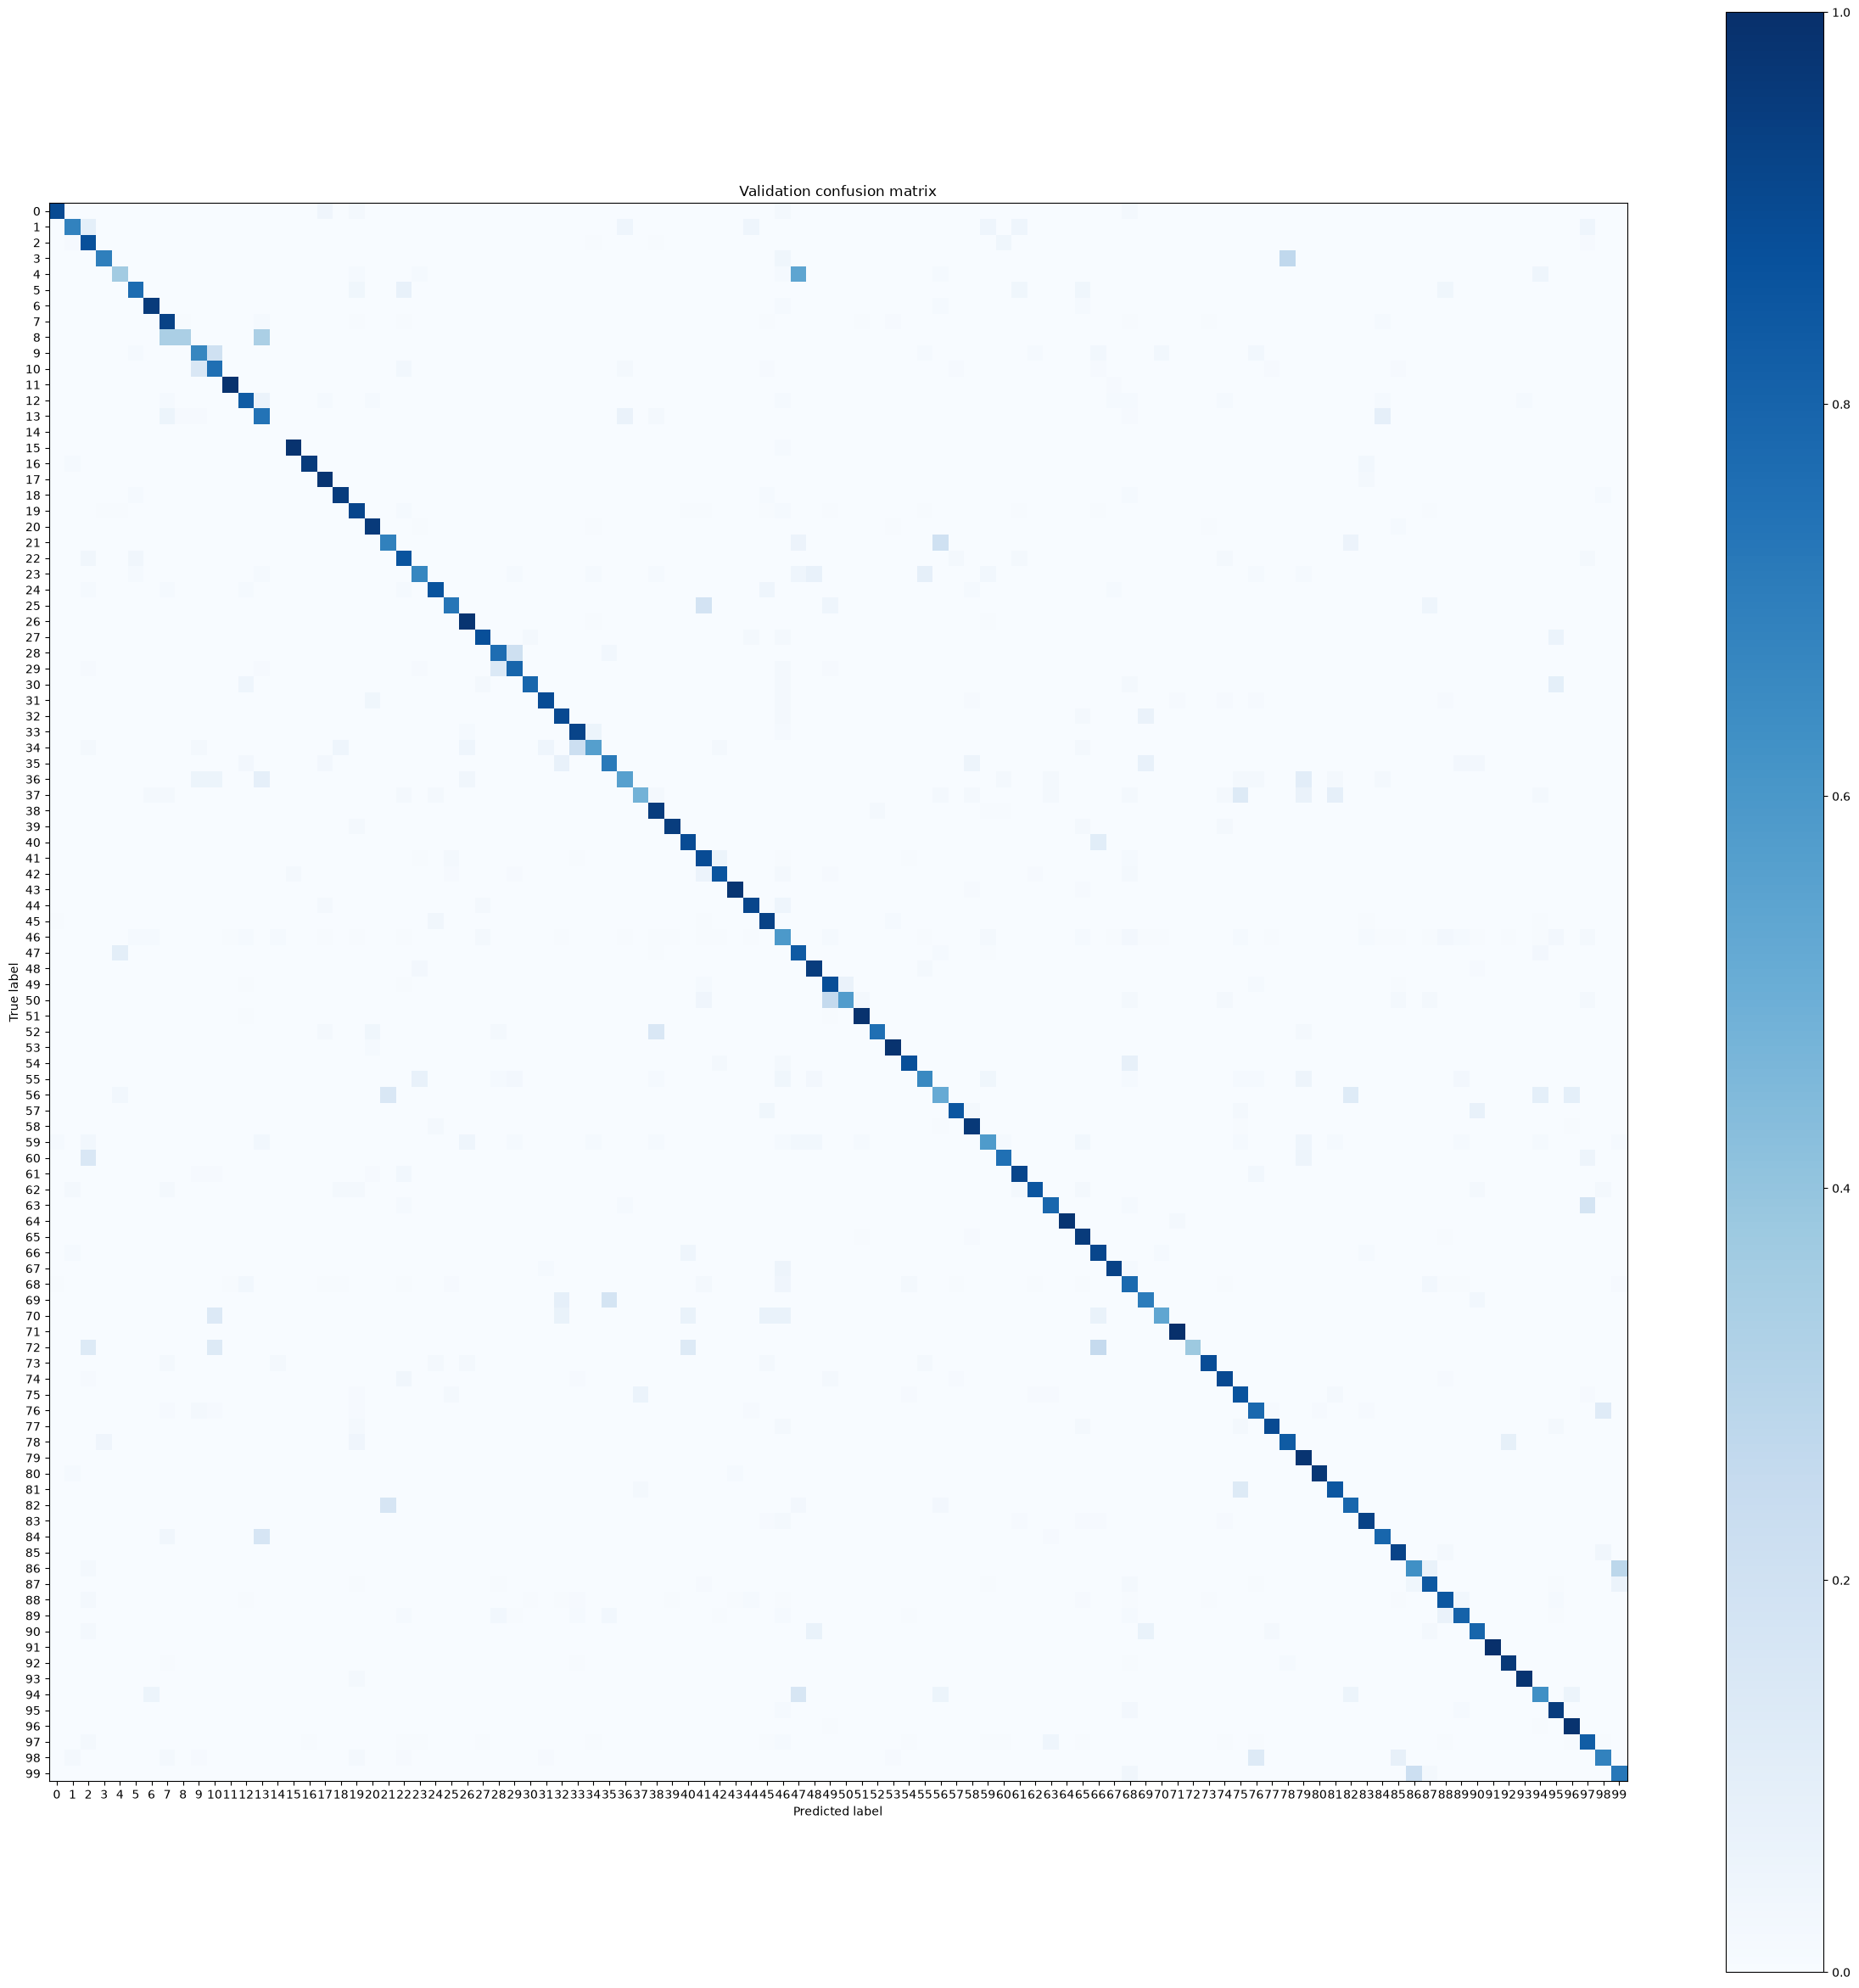

In [23]:
# 6. confusion matrix picture (quick overview only - use step 3 for the details)
ea.plot_confusion_matrix(size=30)

CHANGED FROM (1,2) - NGRAMS (uni and bi) to (1,3) - NGRAMS (uni, bi, and tri)
    - this decreased the error between waivers and no waivers classes
    - no change in applicable law and governing law - this shows that there is a different discrepency between them that the model misses

### 7b. Complement Naive Bayes

In [25]:
ea_cnb = ErrorAnalysis(y_true=y_val, y_pred=val_preds_cnb,
                       label_names=label_names,
                       classes=cnb.model.classes_,
                       texts=proc_val["text"])

display([ea_cnb.report_df().head(15),     # worst clause types
         ea_cnb.top_confusions(n=15)])     # most common mix-ups

[                 precision    recall  f1-score  support
 Applicable Laws   0.000000  0.000000  0.000000       69
 Assigns           0.000000  0.000000  0.000000        3
 Books             0.000000  0.000000  0.000000        0
 Venues            0.666667  0.105263  0.181818       19
 Enforcements      0.833333  0.108696  0.192308       46
 Miscellaneous     0.533333  0.119403  0.195122       67
 Qualifications    1.000000  0.125000  0.222222        8
 Powers            1.000000  0.133333  0.235294       15
 Costs             1.000000  0.136364  0.240000       22
 Effectiveness     0.800000  0.173913  0.285714       46
 Jurisdictions     1.000000  0.181818  0.307692       33
 Modifications     0.846154  0.275000  0.415094       40
 Positions         0.600000  0.352941  0.444444       34
 Enforceability    0.628571  0.385965  0.478261       57
 Indemnity         0.894737  0.361702  0.515152       47,
                 true          predicted  count
 0    Applicable Laws     Governing Law

### 7c. Logistic regression vs Naive Bayes, per clause type
Does Complement NB do better on any clause types (especially small ones)?

In [27]:
per_class = pd.DataFrame({
    "support": ea_cnb.report_df()["support"],
    "LR F1": ea_cnb.report_df()["f1-score"],
    "CNB F1": ea_cnb.report_df()["f1-score"],
})
per_class["CNB - LR"] = per_class["CNB F1"] - per_class["LR F1"]

print("clause types where CNB beats LR:", (per_class["CNB - LR"] > 0).sum())
per_class.sort_values("CNB - LR", ascending=False).head(15).round(3)   # CNB's biggest wins

clause types where CNB beats LR: 0


,support,LR F1,CNB F1,CNB - LR
Applicable Laws,69,0.000,0.000,0.0
Assigns,3,0.000,0.000,0.0
Books,0,0.000,0.000,0.0
Venues,19,0.182,0.182,0.0
Enforcements,46,0.192,0.192,0.0
Miscellaneous,67,0.195,0.195,0.0
Qualifications,8,0.222,0.222,0.0
Powers,15,0.235,0.235,0.0
Costs,22,0.240,0.240,0.0
Effectiveness,46,0.286,0.286,0.0


### 7d. Error Analysis Part 2: applicable law and governing law

In [28]:
train = pd.read_parquet("../data/interim/train_eda.parquet")
print("loaded train:", train.shape)   # expect (59933, 5)
overlapping = train[train['label_name'].isin(['Applicable Laws', 'Governing Laws'])]
# they are not labelled differently with the same text == no duplicates 
overlapping["text"].duplicated().any()

loaded train: (59933, 4)


np.False_

Check modelling coefficients - looking at the weights;

In [29]:
# name -> label number (flip your label_names into a lookup)
# flip the label names fictionary around - the key name and then the numerical value encoded
name_to_label = {v: k for k, v in label_names.items()}
classes = list(lr.model.classes_) # 0-99

# feature_names - column headers
# classes - rows 
# values. inside the cells = coefficient 
def class_weights(name):
    row = classes.index(name_to_label[name]) # which row of coef_ co-ordinates the list of model.classes intot he labelled names
    return pd.Series(lr.model.coef_[row], index=feature_names)

gl = class_weights("Governing Laws")
al = class_weights("Applicable Laws")

# 1. top 20 words for each class, side by side
display(pd.DataFrame({
    "Governing Laws": gl.sort_values(ascending=False).head(20).index,
    "Applicable Laws": al.sort_values(ascending=False).head(20).index,
}))

# 2. what separates them: positive = pushes to GL, negative = pushes to AL
diff = (gl - al).sort_values()
print(diff.tail(20))   # most "Governing Laws" words
print(diff.head(20))   # most "Applicable Laws" words

,Governing Laws,Applicable Laws
0,govern,law
1,law,govern
2,law state,law state
3,state,state
4,construe,accordance law
5,conflict,construe
6,conflict law,applicable law
7,accordance law,govern construe enforce
8,govern construe,interpret
9,govern law,applicable


law rule principle               2.392425
accordance law state             2.412166
amendment construe accordance    2.441085
law commonwealth                 2.471893
make govern                      2.505567
enter state                      2.551513
plan govern law                  2.559086
indiana                          2.560235
make                             2.574758
conflict                         2.593659
contract                         2.629825
hereto                           2.652236
note govern construe             2.682922
deem contract                    2.689331
plan award                       2.811755
numtoken govern                  2.817891
letter govern                    2.820031
note                             3.070537
govern                           3.168443
amendment construe               3.606163
dtype: float64
performable                  -5.424138
apply without reference      -5.242331
perform state new            -4.542506
law thereof jurisdiction    

The more positive values: show that the result is governing law, more negative: applicable law:
- count what % of applicable law contains govern; what % of governing contains applicable law, if both are high , an overlap is evident

In [30]:
gov_df = proc_train[proc_train['label'].isin([47])]
app_df = proc_train[proc_train['label'].isin([4])]
app_df[app_df['clean_text'].str.contains(r'\bgovern(?:s|ed|ing)?\b')] # 258
gov_df[gov_df['clean_text'].str.contains('applicable law', case = False)] # 113
len(app_df) # 349
len(gov_df)  #3157

3157

About three-quarters of Applicable Laws clauses are choice-of-law clauses: the same kind of clause as Governing Laws, filed under a different heading.

74% of Applicable Laws clauses are choice-of-law clauses with the same wording as Governing Laws. The labels come from drafters’ headings, so the two classes overlap.

## 8. Save the trained models
So a restart doesn't mean retraining - reload with `joblib.load(...)` and go straight to evaluating.

In [32]:
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(lr.model, models_dir / "logreg_C30_balanced.joblib")
joblib.dump(cnb.model, models_dir / "complement_nb_alpha0.1.joblib")

# to reload later (no retraining):
# lr_model = joblib.load(models_dir / "logreg_C30_balanced.joblib")
# nb_model = joblib.load(models_dir / "complement_nb_alpha0.1.joblib")

['..\\models\\complement_nb_alpha0.1.joblib']

## 9. Test (ONCE, at the very end)
Settings are final - no changes after this. Both final models are scored once, for the results table.

In [33]:
test_preds_lr, test_scores_lr = ev.eval_test(lr.model)
test_preds_cnb, test_scores_cnb = ev.eval_test(cnb.model)

results = pd.DataFrame({
    "Logistic regression": {"val macro F1": scores_lr["validation"]["macro_f1"],
                            "test macro F1": test_scores_lr["macro_f1"],
                            "test accuracy": test_scores_lr["accuracy"]},
    "Complement NB": {"val macro F1": scores_cnb["validation"]["macro_f1"],
                      "test macro F1": test_scores_cnb["macro_f1"],
                      "test accuracy": test_scores_cnb["accuracy"]},
}).T.round(4)
results

test       accuracy 0.8657 | macro F1 0.8180 | error 0.1820
test       accuracy 0.8226 | macro F1 0.7272 | error 0.2728


,val macro F1,test macro F1,test accuracy
Logistic regression,0.8111,0.8180,0.8657
Complement NB,0.7160,0.7272,0.8226
